# Step 2. Train C2, D1 and D2

This notebook continues **`step1_data.ipynb`**. It trains only these three runs:

| Run | Classifier | Image processing |
|---|---|---|
| **C2** | Colour histograms + local binary patterns (LBP), then an RBF SVM | CLAHE, then median filtering |
| **D1** | ImageNet-pretrained ResNet-18 | CLAHE |
| **D2** | The same ResNet-18 architecture and training procedure | CLAHE, then median filtering |

We load the existing leaf-grouped split and processing settings. We do **not** create a new split,
rewrite Step 1 outputs, or train on the corrupted test copies. All parameter and checkpoint selection
uses **validation macro-F1**. Test evaluation belongs in Step 3.

Run the cells from top to bottom. **`REQUIRE_CUDA = True` requires D1/D2 to use the CUDA GPU**
selected by `CUDA_DEVICE_INDEX` (0 by default). Setup stops if CUDA is unavailable, instead of
silently falling back to CPU. C2's scikit-learn SVM and image preprocessing still run on CPU.

The selected Jupyter kernel must have a CUDA-enabled PyTorch build and compatible torchvision.
A CPU-only PyTorch build cannot use an NVIDIA GPU. Follow the
[official Windows/CUDA installation selector](https://pytorch.org/get-started/locally/) for the
kernel's Python environment, then restart the kernel. Setup reports its Python path if CUDA is
unavailable, and reports the selected GPU name when CUDA is ready. To explicitly allow CPU
fallback later, change `REQUIRE_CUDA` to `False`.

The first CNN run downloads the official ImageNet weights into `outputs/cache/step2/torch/`.

## 2a. Load Step 1 and check the split

Use the same Python environment as Step 1, with `scikit-learn`, `scikit-image`, `joblib`,
`torch`, and a compatible `torchvision` also installed. This notebook does not install packages
or change your Python environment.

The label order stays **healthy, early_blight, late_blight**, matching Step 1. Every saved model
and prediction file records that convention.

In [1]:
import os
import sys
import json
import random
import hashlib
import platform
from copy import deepcopy
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from skimage.feature import local_binary_pattern
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score,
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "outputs" / "manifest.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the project containing outputs/manifest.csv.")

OUT = ROOT / "outputs"
MODEL_DIR = OUT / "models"
TRAINING_DIR = OUT / "training"
FIG_DIR = OUT / "figures" / "step2"
CACHE_DIR = OUT / "cache" / "step2"
for folder in (MODEL_DIR, TRAINING_DIR, FIG_DIR, CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(CACHE_DIR / "torch"))

LABELS = ["healthy", "early_blight", "late_blight"]
CLASS_TO_ID = {label: index for index, label in enumerate(LABELS)}
CLASS_IDS = list(range(len(LABELS)))
SPLITS = ["train", "val", "test"]
RUN_PROCESSING = {"C2": "CLAHE_then_median", "D1": "CLAHE", "D2": "CLAHE_then_median"}
REQUIRE_CUDA = True           # Stop setup if this kernel cannot use CUDA.
CUDA_DEVICE_INDEX = 0         # Select the first visible NVIDIA GPU.
cuda_available = torch.cuda.is_available()
if REQUIRE_CUDA and not cuda_available:
    raise RuntimeError(
        "CUDA is required for D1/D2, but this Jupyter kernel cannot use it.\n"
        f"Kernel Python: {sys.executable}\n"
        f"PyTorch: {torch.__version__}; compiled CUDA: {torch.version.cuda}\n"
        "Install matching CUDA-enabled torch and torchvision in this environment, "
        "or select a kernel that already has them, then restart the kernel.\n"
        "Installation guide: https://pytorch.org/get-started/locally/"
    )
if cuda_available:
    if not isinstance(CUDA_DEVICE_INDEX, int) or not 0 <= CUDA_DEVICE_INDEX < torch.cuda.device_count():
        raise ValueError(f"CUDA_DEVICE_INDEX={CUDA_DEVICE_INDEX!r} is not a visible GPU index.")
    torch.cuda.set_device(CUDA_DEVICE_INDEX)
    DEVICE = torch.device(f"cuda:{CUDA_DEVICE_INDEX}")
else:
    DEVICE = torch.device("cpu")
torch.set_num_threads(min(8, os.cpu_count() or 1))

# Keep the complete grid from your RBF SVM example. The score here is macro-F1.
SVM_GRID = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "gamma": [0.0001, 0.001, 0.01, 1, 10, 100, 1000],
}
FEATURE_CONFIG = {
    "image_size": [256, 256],
    "colour_space": "HSV",
    "histogram_bins_per_channel": 32,
    "lbp_points": 8,
    "lbp_radius": 1,
    "lbp_method": "uniform",
}
CNN_CONFIG = {
    "batch_size": 32,
    "head_epochs": 10,
    "finetune_epochs": 10,
    "head_lr": 1e-3,
    "finetune_lr": 1e-4,
    "patience": 3,
    "use_class_weights": False,
    "num_workers": 0,             # Works inside Windows notebooks without worker pickling.
    "cache_processed_images": True,
}

print("Project:", ROOT)
print("Kernel Python:", sys.executable)
print("PyTorch:", torch.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(DEVICE), "| CUDA runtime:", torch.version.cuda)
print("Label IDs:", CLASS_TO_ID)

Project: c:\Users\user\DImProj
Kernel Python: c:\Users\user\AppData\Local\Programs\Python\Python313\python.exe
PyTorch: 2.12.0+cu130 | device: cuda:0
GPU: NVIDIA GeForce RTX 4060 Laptop GPU | CUDA runtime: 13.0
Label IDs: {'healthy': 0, 'early_blight': 1, 'late_blight': 2}


In [2]:
def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def write_json(path, payload):
    Path(path).write_text(json.dumps(payload, indent=2, allow_nan=False), encoding="utf-8")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


def resolve_image_path(saved_path):
    # Step 1's actual CSV contains Windows absolute paths. Also accept portable paths
    # and manifests moved to another computer, always preferring this project's dataset.
    normalized = str(saved_path).replace("\\", "/")
    parts = normalized.split("/")
    if "PlantVillage-Dataset" in parts:
        local = ROOT.joinpath(*parts[parts.index("PlantVillage-Dataset"):])
        if local.is_file():
            return local
    candidate = Path(normalized)
    if not candidate.is_absolute():
        candidate = ROOT / candidate
    if not candidate.is_file():
        raise FileNotFoundError(f"Manifest image not found: {saved_path}")
    return candidate


MANIFEST_PATH = OUT / "manifest.csv"
SETTINGS_PATH = OUT / "processing_settings.json"
with SETTINGS_PATH.open(encoding="utf-8") as stream:
    SETTINGS = json.load(stream)

for key in ("clahe_clip", "clahe_grid", "median_k", "seed"):
    if key not in SETTINGS:
        raise ValueError(f"Step 1 processing settings are missing {key!r}.")
if not np.isfinite(SETTINGS["clahe_clip"]) or SETTINGS["clahe_clip"] <= 0:
    raise ValueError("CLAHE clip limit must be positive and finite.")
for key in ("clahe_grid", "median_k"):
    if not isinstance(SETTINGS[key], int) or SETTINGS[key] <= 0:
        raise ValueError(f"{key} must be a positive integer.")
if SETTINGS["median_k"] < 3 or SETTINGS["median_k"] % 2 != 1:
    raise ValueError("The median kernel must be an odd integer of at least 3.")
SEED = int(SETTINGS["seed"])
seed_everything(SEED)

manifest = pd.read_csv(MANIFEST_PATH)
required_columns = {"path", "label", "leaf_id", "split"}
if not required_columns.issubset(manifest.columns):
    raise ValueError(f"Manifest needs columns: {sorted(required_columns)}")
if manifest[list(required_columns)].isna().any().any():
    raise ValueError("Manifest paths, labels, leaf IDs and splits cannot be missing.")
if manifest["path"].duplicated().any():
    raise ValueError("The manifest contains duplicate image paths.")
if set(manifest["label"]) != set(LABELS) or set(manifest["split"]) != set(SPLITS):
    raise ValueError("Unexpected labels or partitions in the Step 1 manifest.")
if manifest.groupby("leaf_id")["split"].nunique().gt(1).any():
    raise ValueError("A leaf occurs in more than one partition.")
if manifest.groupby("leaf_id")["label"].nunique().gt(1).any():
    raise ValueError("A leaf has inconsistent labels.")

# Resolve filenames only: no test image pixels are loaded in Step 2.
manifest["full_path"] = manifest["path"].map(resolve_image_path)
manifest["target"] = manifest["label"].map(CLASS_TO_ID).astype(int)
split_counts = pd.crosstab(manifest["label"], manifest["split"]).reindex(index=LABELS, columns=SPLITS)
if split_counts.isna().any().any() or split_counts.le(0).any().any():
    raise ValueError("Every class must occur in each partition.")
saved_counts_path = OUT / "figures" / "split_counts.csv"
if saved_counts_path.is_file():
    saved_counts = pd.read_csv(saved_counts_path, index_col=0).reindex(index=LABELS, columns=SPLITS)
    if not np.array_equal(split_counts.to_numpy(), saved_counts.to_numpy()):
        raise ValueError("The manifest disagrees with Step 1's saved count table.")

train_frame = manifest.loc[manifest["split"].eq("train")].reset_index(drop=True)
val_frame = manifest.loc[manifest["split"].eq("val")].reset_index(drop=True)
SOURCE_HASHES = {
    "manifest_sha256": file_sha256(MANIFEST_PATH),
    "processing_settings_sha256": file_sha256(SETTINGS_PATH),
}
PACKAGE_VERSIONS = {
    name: version(name)
    for name in ("numpy", "pandas", "opencv-python", "Pillow", "scikit-learn",
                 "scikit-image", "joblib", "torch", "torchvision", "matplotlib")
}

display(split_counts.assign(total=split_counts.sum(axis=1)))
print("Training images:", len(train_frame), "| validation images:", len(val_frame))
print("Processing settings:", SETTINGS)
print("All leaf groups are isolated. Test images remain reserved for Step 3.")

split,train,val,test,total
label,,,,
healthy,699,152,148,999
early_blight,699,152,148,999
late_blight,644,136,140,920


Training images: 2042 | validation images: 440
Processing settings: {'clahe_clip': 2.0, 'clahe_grid': 8, 'median_k': 3, 'seed': 42, 'note': 'Chosen on validation photos only (Step 1c).'}
All leaf groups are isolated. Test images remain reserved for Step 3.


## 2b. Apply the saved image processing

These are the same operations as Step 1: CLAHE changes the **L channel of CIELAB**, and the
median filter acts on the resulting RGB image. Their parameters come directly from the saved JSON.
We do not retune or overwrite them here.

Following Step 1's explicit size plan, processing and classical features use **256 x 256** images;
the CNN uses the pretrained weights' **224 x 224 centre crop** and ImageNet normalization.
This retains Step 1's size convention rather than changing its planned crop to the proposal's
generic resize. D1 and D2 have identical geometry and normalization.

In [3]:
def load_rgb(path):
    with Image.open(path) as image:
        image = image.convert("RGB")
        if image.size != (256, 256):
            raise ValueError(f"Expected Step 1's 256 x 256 image, got {image.size}: {path}")
        return np.array(image)


def apply_clahe(rgb, clip, grid):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lightness, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid))
    enhanced = clahe.apply(lightness)
    return cv2.cvtColor(cv2.merge([enhanced, a, b]), cv2.COLOR_LAB2RGB)


def apply_median(rgb, k):
    return cv2.medianBlur(rgb, k)


def process_rgb(rgb, run):
    if run not in RUN_PROCESSING:
        raise ValueError(f"Only C2, D1 and D2 are supported, got {run!r}.")
    enhanced = apply_clahe(rgb, SETTINGS["clahe_clip"], SETTINGS["clahe_grid"])
    if run in ("C2", "D2"):
        enhanced = apply_median(enhanced, SETTINGS["median_k"])
    return enhanced


def assert_training_partitions(training, validation):
    # Recheck the boundary when a training function is called directly.
    if set(training["split"]) != {"train"} or set(validation["split"]) != {"val"}:
        raise ValueError("Training accepts train rows and validation accepts val rows only.")
    if set(training["leaf_id"]) & set(validation["leaf_id"]):
        raise ValueError("Training and validation share a leaf.")


def run_metadata(run):
    return {
        "run": run,
        "processing": RUN_PROCESSING[run],
        "processing_settings": deepcopy(SETTINGS),
        "labels": LABELS,
        "class_to_id": CLASS_TO_ID,
        "seed": SEED,
        "selection_metric": "validation_macro_f1",
        "source_hashes": SOURCE_HASHES,
        "split_counts": split_counts.to_dict(),
        "python_version": platform.python_version(),
        "package_versions": PACKAGE_VERSIONS,
        "device": "cpu" if run == "C2" else str(DEVICE),
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "test_evaluated": False,
    }

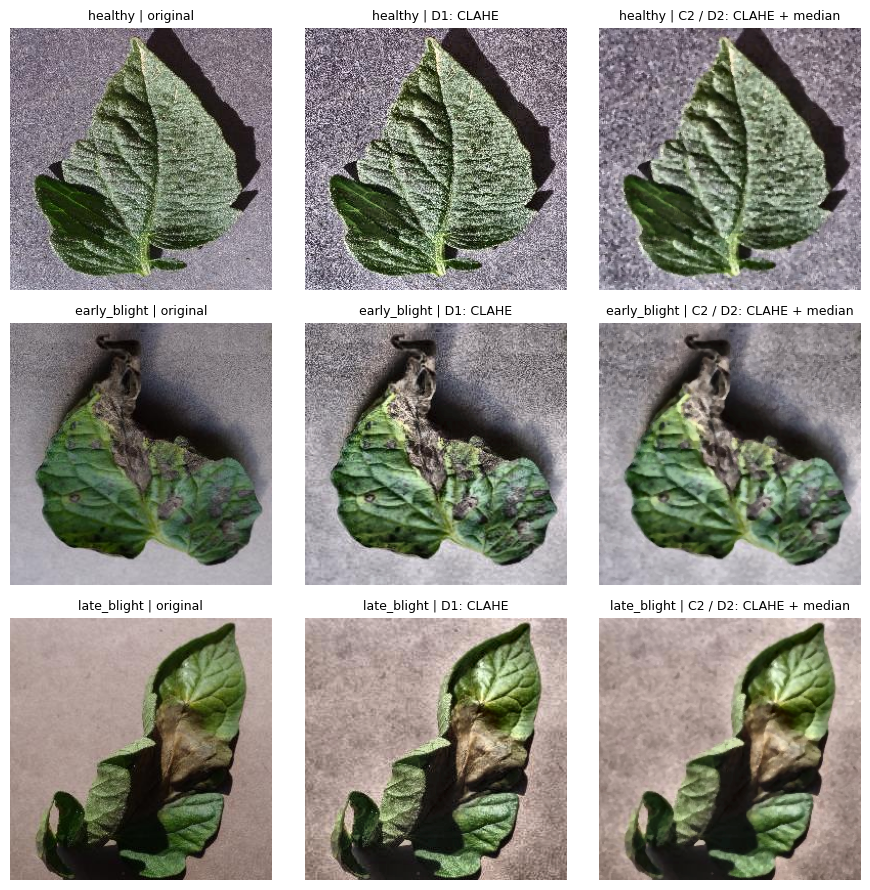

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row, label in enumerate(LABELS):
    sample = train_frame.loc[train_frame["label"].eq(label)].iloc[0]
    rgb = load_rgb(sample["full_path"])
    panels = {"original": rgb, "D1: CLAHE": process_rgb(rgb, "D1"),
              "C2 / D2: CLAHE + median": process_rgb(rgb, "D2")}
    for column, (title, image) in enumerate(panels.items()):
        axes[row, column].imshow(image)
        axes[row, column].set_title(f"{label} | {title}", fontsize=9)
        axes[row, column].axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "training_processing_preview.png", dpi=150)
plt.show()

### Shared validation reports

Each run saves per-image **validation** predictions, accuracy, macro-F1, per-class precision/recall,
and a confusion matrix. These scores are used for model selection; they are not final test results.

In [5]:
def metric_summary(truth, predictions):
    return {
        "val_accuracy": float(accuracy_score(truth, predictions)),
        "val_macro_f1": float(f1_score(
            truth, predictions, labels=CLASS_IDS, average="macro", zero_division=0,
        )),
    }


def save_validation_outputs(run, frame, predictions, scores, score_kind):
    truth = frame["target"].to_numpy()
    predictions = np.asarray(predictions, dtype=int)
    scores = np.asarray(scores)
    if predictions.shape != truth.shape or scores.shape != (len(frame), len(LABELS)):
        raise ValueError("Prediction rows or class-score columns do not match the validation data.")
    run_dir = TRAINING_DIR / run
    run_dir.mkdir(parents=True, exist_ok=True)
    table = frame[["path", "leaf_id", "split", "label", "target"]].copy()
    table["prediction_id"] = predictions
    table["prediction"] = [LABELS[index] for index in predictions]
    table["correct"] = predictions == truth
    for index, label in enumerate(LABELS):
        table[f"{score_kind}_{label}"] = scores[:, index]
    table.to_csv(run_dir / "validation_predictions.csv", index=False)

    report = classification_report(
        truth, predictions, labels=CLASS_IDS, target_names=LABELS,
        output_dict=True, zero_division=0,
    )
    write_json(run_dir / "validation_classification_report.json", report)
    matrix = confusion_matrix(truth, predictions, labels=CLASS_IDS)
    pd.DataFrame(matrix, index=LABELS, columns=LABELS).rename_axis("true_label").to_csv(
        run_dir / "validation_confusion_matrix.csv",
    )
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=20,
    )
    ax.set_title(f"{run}: validation confusion matrix")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{run}_validation_confusion_matrix.png", dpi=150)
    plt.close(fig)
    return metric_summary(truth, predictions)

## 2c. C2: colour and texture features, then an RBF SVM

The feature vector has **106 values**:

- Three normalized **HSV histograms**, each with 32 bins: 96 colour values. Hue describes colour;
  saturation describes colour strength; value describes brightness.
- One normalized **uniform LBP histogram**, with 8 neighbours and radius 1: 10 texture values.
  It describes small local intensity patterns, including flat areas, edges and spots.

These fixed descriptors need no fitted statistics. The **StandardScaler does**: it is fitted inside
the pipeline using training rows only. Validation rows are transformed with the same fitted scaler.

We keep your example's C/gamma candidates, but evaluate each pair against the **existing validation
partition**, using macro-F1. Ordinary three-fold CV would replace the saved validation protocol and
could split photos of the same leaf. The winning pipeline remains fitted on **training data only**;
there is no automatic refit on combined training and validation rows.

In [6]:
def extract_features(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    bins = FEATURE_CONFIG["histogram_bins_per_channel"]
    features = []
    for channel, upper in enumerate((180, 256, 256)):
        histogram = cv2.calcHist([hsv], [channel], None, [bins], [0, upper]).ravel()
        features.append(histogram / histogram.sum())

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)  # uint8 avoids floating-point LBP artefacts.
    points = FEATURE_CONFIG["lbp_points"]
    lbp = local_binary_pattern(
        gray, P=points, R=FEATURE_CONFIG["lbp_radius"], method=FEATURE_CONFIG["lbp_method"],
    )
    texture = np.bincount(lbp.astype(np.int64).ravel(), minlength=points + 2).astype(np.float32)
    features.append(texture / texture.sum())
    result = np.concatenate(features).astype(np.float32)
    if result.shape != (3 * bins + points + 2,) or not np.isfinite(result).all():
        raise ValueError("Invalid colour/LBP feature vector.")
    return result


def feature_matrix(frame):
    rows = []
    for number, path in enumerate(frame["full_path"], start=1):
        rows.append(extract_features(process_rgb(load_rgb(path), "C2")))
        if number % 500 == 0:
            print(f"C2 features: {number}/{len(frame)}")
    return np.stack(rows)


def plot_svm_search(search_table):
    # Pivot by named parameters: avoid the swapped axes in a reshape-based heatmap.
    grid = search_table.pivot(index="C", columns="gamma", values="val_macro_f1").reindex(
        index=SVM_GRID["C"], columns=SVM_GRID["gamma"],
    )
    fig, ax = plt.subplots(figsize=(10, 7))
    image = ax.imshow(grid.to_numpy(), cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(grid.columns)), [str(value) for value in grid.columns], rotation=45)
    ax.set_yticks(range(len(grid.index)), [str(value) for value in grid.index])
    for row in range(len(grid.index)):
        for column in range(len(grid.columns)):
            value = grid.iloc[row, column]
            ax.text(column, row, f"{value:.3f}", ha="center", va="center",
                    color="black" if value > 0.65 else "white", fontsize=8)
    ax.set(xlabel="gamma", ylabel="C", title="C2: validation macro-F1 for each RBF SVM")
    fig.colorbar(image, ax=ax, label="Validation macro-F1")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "C2_parameter_heatmap.png", dpi=150)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 5))
    for gamma, group in search_table.groupby("gamma", sort=True):
        group = group.sort_values("C")
        ax.plot(group["C"], group["val_macro_f1"], "o-", label=f"gamma={gamma:g}")
    ax.set(xscale="log", xlabel="C", ylabel="Validation macro-F1",
           title="C2: validation macro-F1 versus C", ylim=(0, 1.02))
    ax.legend(title="RBF kernel", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "C2_macro_f1_vs_C.png", dpi=150)
    plt.show()


def train_c2(training, validation, parameter_grid=None):
    assert_training_partitions(training, validation)
    start = perf_counter()
    X_train = feature_matrix(training)
    X_val = feature_matrix(validation)
    y_train = training["target"].to_numpy()
    y_val = validation["target"].to_numpy()

    records, best_pipeline, best_parameters = [], None, None
    best_score = -1.0
    candidates = list(ParameterGrid(SVM_GRID if parameter_grid is None else parameter_grid))
    for number, parameters in enumerate(candidates, start=1):
        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", SVC(kernel="rbf", C=parameters["C"], gamma=parameters["gamma"],
                        decision_function_shape="ovr", cache_size=256)),
        ])
        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_val)
        metrics = metric_summary(y_val, predictions)
        records.append({"C": float(parameters["C"]), "gamma": float(parameters["gamma"]), **metrics})
        # First candidate wins an exact tie: ParameterGrid's order is deterministic.
        if metrics["val_macro_f1"] > best_score:
            best_score = metrics["val_macro_f1"]
            best_pipeline, best_parameters = pipeline, dict(parameters)
        print(f"C2 {number:02d}/{len(candidates)}: C={parameters['C']:g}, "
              f"gamma={parameters['gamma']:g}, val macro-F1={metrics['val_macro_f1']:.4f}")

    search_table = pd.DataFrame(records)
    run_dir = TRAINING_DIR / "C2"
    run_dir.mkdir(parents=True, exist_ok=True)
    search_table.to_csv(run_dir / "parameter_search.csv", index=False)
    if int(best_pipeline.named_steps["scaler"].n_samples_seen_) != len(training):
        raise RuntimeError("The selected scaler was not fitted on exactly the training rows.")
    model_path = MODEL_DIR / "C2.joblib"
    joblib.dump(best_pipeline, model_path)
    predictions = best_pipeline.predict(X_val)
    metrics = save_validation_outputs(
        "C2", validation, predictions, best_pipeline.decision_function(X_val), "decision",
    )
    summary = {"run": "C2", "model": "HSV_LBP_RBF_SVM", "processing": RUN_PROCESSING["C2"],
               **metrics, "training_seconds": perf_counter() - start,
               "checkpoint": str(model_path.relative_to(ROOT))}
    metadata = {**run_metadata("C2"), "feature_config": deepcopy(FEATURE_CONFIG),
                "parameter_grid": deepcopy(SVM_GRID if parameter_grid is None else parameter_grid),
                "selected_parameters": best_parameters, "training_images": len(training),
                "validation_images": len(validation), "summary": summary,
                "score_columns": "Uncalibrated SVM decision values; not probabilities."}
    write_json(MODEL_DIR / "C2_metadata.json", metadata)
    write_json(run_dir / "summary.json", summary)
    return {"summary": summary, "search_table": search_table}

C2 features: 500/2042
C2 features: 1000/2042
C2 features: 1500/2042
C2 features: 2000/2042
C2 01/49: C=0.001, gamma=0.0001, val macro-F1=0.4627
C2 02/49: C=0.001, gamma=0.001, val macro-F1=0.4949
C2 03/49: C=0.001, gamma=0.01, val macro-F1=0.5587
C2 04/49: C=0.001, gamma=1, val macro-F1=0.1712
C2 05/49: C=0.001, gamma=10, val macro-F1=0.5561
C2 06/49: C=0.001, gamma=100, val macro-F1=0.2026
C2 07/49: C=0.001, gamma=1000, val macro-F1=0.1712
C2 08/49: C=0.01, gamma=0.0001, val macro-F1=0.4627
C2 09/49: C=0.01, gamma=0.001, val macro-F1=0.4949
C2 10/49: C=0.01, gamma=0.01, val macro-F1=0.6978
C2 11/49: C=0.01, gamma=1, val macro-F1=0.1712
C2 12/49: C=0.01, gamma=10, val macro-F1=0.5561
C2 13/49: C=0.01, gamma=100, val macro-F1=0.2026
C2 14/49: C=0.01, gamma=1000, val macro-F1=0.1712
C2 15/49: C=0.1, gamma=0.0001, val macro-F1=0.4765
C2 16/49: C=0.1, gamma=0.001, val macro-F1=0.9140
C2 17/49: C=0.1, gamma=0.01, val macro-F1=0.9443
C2 18/49: C=0.1, gamma=1, val macro-F1=0.1712
C2 19/49: C=

,C,gamma,val_accuracy,val_macro_f1
29,10.0,0.0010,0.984091,0.983709
35,100.0,0.0001,0.981818,0.981395
23,1.0,0.0100,0.979545,0.979089
37,100.0,0.0100,0.975000,0.974477
44,1000.0,0.0100,0.975000,0.974477
36,100.0,0.0010,0.970455,0.969838
30,10.0,0.0100,0.970455,0.969838
42,1000.0,0.0001,0.970455,0.969833
43,1000.0,0.0010,0.968182,0.967501
22,1.0,0.0010,0.965909,0.965149


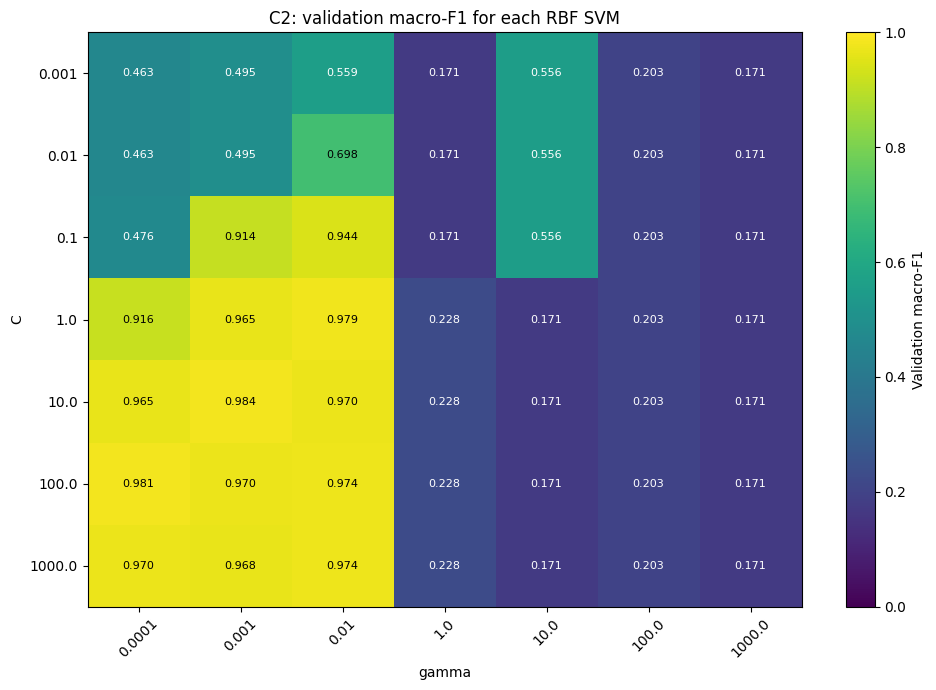

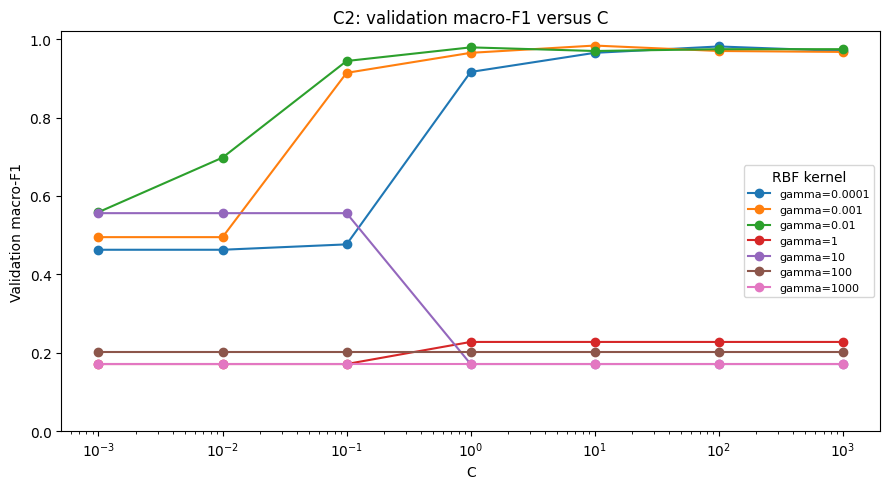

Selected C2: {'run': 'C2', 'model': 'HSV_LBP_RBF_SVM', 'processing': 'CLAHE_then_median', 'val_accuracy': 0.9840909090909091, 'val_macro_f1': 0.9837092009309666, 'training_seconds': 32.0542204999947, 'checkpoint': 'outputs\\models\\C2.joblib'}


In [7]:
c2_result = train_c2(train_frame, val_frame)
display(c2_result["search_table"].sort_values("val_macro_f1", ascending=False).head(10))
plot_svm_search(c2_result["search_table"])
print("Selected C2:", c2_result["summary"])

## 2d. D1 and D2: transfer learning with ResNet-18

Both runs start independently from **the same ImageNet weights**, random seed, classifier
initialization, data order, and geometric augmentation. D2 is not initialized from the trained D1.
Only their deterministic image processing differs.

| Component | Output |
|---|---|
| Normalized RGB input | 3 x 224 x 224 |
| Initial convolution and pooling | 64 x 56 x 56 |
| Four residual stages | 64 x 56 x 56; 128 x 28 x 28; 256 x 14 x 14; 512 x 7 x 7 |
| Global average pooling | 512 features |
| Replacement linear classifier | 3 logits |

**Phase 1:** freeze the backbone and train the new classifier using Adam at 0.001.
**Phase 2:** restore the best Phase 1 weights, then train `layer4` and the classifier using
Adam at 0.0001. Earlier stages stay frozen, including their batch-normalization running statistics.

Each phase runs for at most 10 epochs, with early stopping after 3 epochs without a higher
validation macro-F1. The overall best checkpoint can come from either phase. Cross-entropy
consumes raw logits and integer class IDs; softmax is used only when saving prediction probabilities.

Training augmentation is a horizontal flip with probability 0.5 for both D1 and D2. Validation
has no random augmentation. Optional loss weights, if enabled above, come from training counts only.

In [8]:
WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1
EVAL_TRANSFORM = WEIGHTS.transforms()  # Resize 256, centre crop 224, tensor, ImageNet normalization.
TRAIN_TRANSFORM = transforms.Compose([transforms.RandomHorizontalFlip(p=0.5), EVAL_TRANSFORM])


class LeafDataset(Dataset):
    def __init__(self, frame, run, training=False, cache_processed_images=True):
        allowed_split = "train" if training else "val"
        if set(frame["split"]) != {allowed_split}:
            raise ValueError(f"This dataset expects {allowed_split!r} rows only.")
        if run not in ("D1", "D2"):
            raise ValueError("The CNN dataset supports D1 and D2 only.")
        self.frame = frame.reset_index(drop=True)
        self.run = run
        self.transform = TRAIN_TRANSFORM if training else EVAL_TRANSFORM
        # Cache only deterministic uint8 images, never random augmented tensors.
        self.images = None
        if cache_processed_images:
            self.images = [process_rgb(load_rgb(path), run) for path in self.frame["full_path"]]

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image = self.images[index] if self.images is not None else process_rgb(load_rgb(row["full_path"]), self.run)
        return self.transform(Image.fromarray(image)), int(row["target"])


def create_resnet18():
    # Fails visibly if pretrained weights cannot be fetched; never substitutes random weights.
    model = models.resnet18(weights=WEIGHTS)
    for parameter in model.parameters():
        parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, len(LABELS))
    return model


def configure_phase(model, phase):
    if phase not in ("head", "finetune"):
        raise ValueError(f"Unknown phase: {phase}")
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.fc.parameters():
        parameter.requires_grad = True
    if phase == "finetune":
        for parameter in model.layer4.parameters():
            parameter.requires_grad = True


def set_training_mode(model, phase):
    # requires_grad alone does not freeze BatchNorm's running mean and variance.
    model.eval()
    model.fc.train()
    if phase == "finetune":
        model.layer4.train()


def make_loaders(training, validation, run, config):
    training_data = LeafDataset(training, run, training=True,
                                cache_processed_images=config["cache_processed_images"])
    validation_data = LeafDataset(validation, run, training=False,
                                  cache_processed_images=config["cache_processed_images"])
    generator = torch.Generator().manual_seed(SEED)
    options = {"batch_size": config["batch_size"], "num_workers": config["num_workers"],
               "pin_memory": DEVICE.type == "cuda"}
    training_loader = DataLoader(training_data, shuffle=True, generator=generator, **options)
    validation_loader = DataLoader(validation_data, shuffle=False, **options)
    return training_loader, validation_loader


def make_criterion(training, use_class_weights):
    counts = np.bincount(training["target"].to_numpy(), minlength=len(LABELS))
    if (counts == 0).any():
        raise ValueError("Every class needs training examples.")
    weights = None
    if use_class_weights:
        weights = torch.tensor(len(training) / (len(LABELS) * counts), dtype=torch.float32, device=DEVICE)
    return nn.CrossEntropyLoss(weight=weights)


def run_epoch(model, loader, criterion, optimizer=None, phase=None):
    training = optimizer is not None
    if training:
        set_training_mode(model, phase)
    else:
        model.eval()
    loss_sum, sample_count, truths, predictions = 0.0, 0, [], []
    with torch.set_grad_enabled(training):
        for images, targets in loader:
            images = images.to(DEVICE, non_blocking=DEVICE.type == "cuda")
            targets = targets.to(DEVICE, non_blocking=DEVICE.type == "cuda")
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                optimizer.step()
            batch_size = len(targets)
            loss_sum += float(loss.detach().cpu()) * batch_size
            sample_count += batch_size
            truths.extend(targets.detach().cpu().tolist())
            predictions.extend(logits.detach().argmax(dim=1).cpu().tolist())
    metrics = metric_summary(truths, predictions)
    return {"loss": loss_sum / sample_count, "accuracy": metrics["val_accuracy"],
            "macro_f1": metrics["val_macro_f1"]}


def predict_cnn(model, loader):
    model.eval()
    probabilities = []
    with torch.inference_mode():
        for images, _ in loader:
            logits = model(images.to(DEVICE, non_blocking=DEVICE.type == "cuda"))
            probabilities.append(logits.softmax(dim=1).cpu().numpy())
    probabilities = np.concatenate(probabilities)
    return probabilities.argmax(axis=1), probabilities


def cpu_state(model):
    return {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}


def plot_learning_curves(run, history):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric, title in zip(axes, ("loss", "macro_f1", "accuracy"),
                                ("Cross-entropy", "Macro-F1", "Accuracy")):
        ax.plot(history["epoch"], history[f"train_{metric}"], "o-", label="train")
        ax.plot(history["epoch"], history[f"val_{metric}"], "o-", label="validation")
        phase2 = history.loc[history["phase"].eq("finetune"), "epoch"]
        if len(phase2):
            ax.axvline(phase2.iloc[0] - 0.5, color="gray", linestyle="--", label="fine-tuning starts")
        ax.set(xlabel="Epoch", ylabel=title, title=f"{run}: {title}")
        if metric != "loss":
            ax.set_ylim(0, 1.02)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{run}_learning_curves.png", dpi=150)
    plt.show()

In [9]:
def train_deep(run, training, validation, config=None):
    if run not in ("D1", "D2"):
        raise ValueError("train_deep accepts D1 and D2 only.")
    assert_training_partitions(training, validation)
    config = deepcopy(CNN_CONFIG if config is None else config)
    for key in ("head_epochs", "finetune_epochs"):
        if not 1 <= config[key] <= 10:
            raise ValueError(f"{key} must be between 1 and 10, following the proposal.")
    if config["patience"] < 1 or config["batch_size"] < 1:
        raise ValueError("Patience and batch size must be positive.")

    # Reset before each run: identical new-head initialization and shuffle/augmentation seeds.
    seed_everything(SEED)
    start = perf_counter()
    model = create_resnet18().to(DEVICE)
    training_loader, validation_loader = make_loaders(training, validation, run, config)
    criterion = make_criterion(training, config["use_class_weights"])
    run_dir = TRAINING_DIR / run
    run_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = MODEL_DIR / f"{run}_best.pt"
    metadata = {**run_metadata(run), "architecture": "resnet18", "weights": "IMAGENET1K_V1",
                "classifier_in_features": model.fc.in_features, "classifier_out_features": len(LABELS),
                "cnn_config": config, "training_images": len(training), "validation_images": len(validation),
                "input_transform": {"processing_size": 256, "resize_short_edge": 256, "center_crop": 224,
                                    "mean": list(EVAL_TRANSFORM.mean), "std": list(EVAL_TRANSFORM.std),
                                    "training_horizontal_flip_probability": 0.5},
                "class_weights": None if criterion.weight is None else criterion.weight.detach().cpu().tolist(),
                "frozen_batchnorm_policy": "Frozen stages stay in eval mode; layer4 trains in phase 2."}

    history, overall_best, epoch_number = [], -1.0, 0
    for phase, epochs, learning_rate in (
        ("head", config["head_epochs"], config["head_lr"]),
        ("finetune", config["finetune_epochs"], config["finetune_lr"]),
    ):
        configure_phase(model, phase)
        optimizer = torch.optim.Adam(
            (parameter for parameter in model.parameters() if parameter.requires_grad), lr=learning_rate,
        )
        phase_best, phase_state, stale_epochs = -1.0, None, 0
        trainable_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
        print(f"{run} | {phase} | {trainable_count:,} trainable parameters | lr={learning_rate:g}")
        for phase_epoch in range(1, epochs + 1):
            epoch_number += 1
            epoch_start = perf_counter()
            # Match the geometric random sequence between D1 and D2 at each phase/epoch,
            # even if their previous phase stopped after different numbers of epochs.
            epoch_seed = SEED + (0 if phase == "head" else 1000) + phase_epoch
            torch.manual_seed(epoch_seed)
            training_loader.generator.manual_seed(epoch_seed)
            train_metrics = run_epoch(model, training_loader, criterion, optimizer, phase)
            val_metrics = run_epoch(model, validation_loader, criterion)
            if not all(np.isfinite(value) for value in (*train_metrics.values(), *val_metrics.values())):
                raise RuntimeError(f"Non-finite training or validation metric in {run}.")
            record = {"run": run, "epoch": epoch_number, "phase": phase, "phase_epoch": phase_epoch,
                      "learning_rate": learning_rate, "trainable_parameters": trainable_count,
                      **{f"train_{key}": value for key, value in train_metrics.items()},
                      **{f"val_{key}": value for key, value in val_metrics.items()},
                      "epoch_seconds": perf_counter() - epoch_start}
            history.append(record)
            pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
            print(f"{run} {phase} {phase_epoch:02d}/{epochs}: "
                  f"train loss={train_metrics['loss']:.4f}, "
                  f"val macro-F1={val_metrics['macro_f1']:.4f}, "
                  f"val accuracy={val_metrics['accuracy']:.4f}")

            if val_metrics["macro_f1"] > phase_best:
                phase_best, phase_state, stale_epochs = val_metrics["macro_f1"], cpu_state(model), 0
            else:
                stale_epochs += 1
            if val_metrics["macro_f1"] > overall_best:
                overall_best = val_metrics["macro_f1"]
                torch.save({"model_state_dict": cpu_state(model), "metadata": metadata,
                            "best_phase": phase, "best_epoch": epoch_number,
                            "val_macro_f1": float(overall_best),
                            "val_accuracy": float(val_metrics["accuracy"])}, checkpoint_path)
            if stale_epochs >= config["patience"]:
                print(f"{run}: early stopping {phase}; restoring its best validation checkpoint.")
                break
        # Phase 2 starts from the best head, never simply the final head epoch.
        model.load_state_dict(phase_state)

    best = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(best["model_state_dict"])
    predictions, probabilities = predict_cnn(model, validation_loader)
    metrics = save_validation_outputs(run, validation, predictions, probabilities, "probability")
    if not np.isclose(metrics["val_macro_f1"], best["val_macro_f1"]):
        raise RuntimeError("Reloaded best checkpoint does not reproduce its validation macro-F1.")
    summary = {"run": run, "model": "ResNet18", "processing": RUN_PROCESSING[run], **metrics,
               "training_seconds": perf_counter() - start,
               "checkpoint": str(checkpoint_path.relative_to(ROOT)),
               "best_phase": best["best_phase"], "best_epoch": best["best_epoch"]}
    write_json(MODEL_DIR / f"{run}_metadata.json", {**metadata, "summary": summary})
    write_json(run_dir / "summary.json", summary)
    return {"summary": summary, "history": pd.DataFrame(history)}

D1 | head | 1,539 trainable parameters | lr=0.001
D1 head 01/10: train loss=0.5924, val macro-F1=0.8877, val accuracy=0.8909
D1 head 02/10: train loss=0.3151, val macro-F1=0.9049, val accuracy=0.9068
D1 head 03/10: train loss=0.2613, val macro-F1=0.9284, val accuracy=0.9295
D1 head 04/10: train loss=0.2236, val macro-F1=0.9284, val accuracy=0.9295
D1 head 05/10: train loss=0.1986, val macro-F1=0.9145, val accuracy=0.9159
D1 head 06/10: train loss=0.1934, val macro-F1=0.9119, val accuracy=0.9136
D1: early stopping head; restoring its best validation checkpoint.
D1 | finetune | 8,395,267 trainable parameters | lr=0.0001
D1 finetune 01/10: train loss=0.1476, val macro-F1=0.9678, val accuracy=0.9682
D1 finetune 02/10: train loss=0.0333, val macro-F1=0.9700, val accuracy=0.9705
D1 finetune 03/10: train loss=0.0215, val macro-F1=0.9721, val accuracy=0.9727
D1 finetune 04/10: train loss=0.0138, val macro-F1=0.9793, val accuracy=0.9795
D1 finetune 05/10: train loss=0.0109, val macro-F1=0.9793,

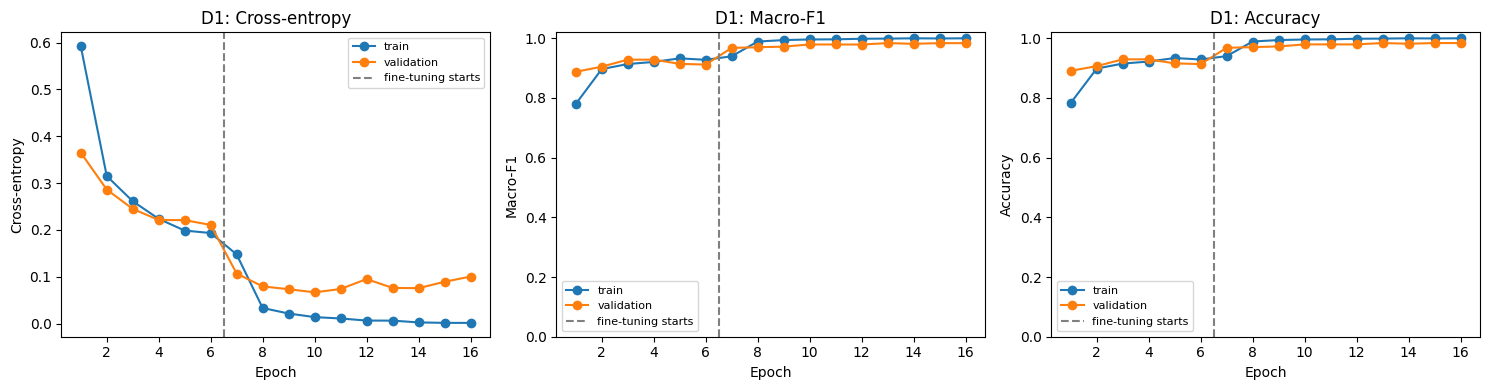

Selected checkpoint: {'run': 'D1', 'model': 'ResNet18', 'processing': 'CLAHE', 'val_accuracy': 0.9840909090909091, 'val_macro_f1': 0.9838533925716583, 'training_seconds': 166.43346119999478, 'checkpoint': 'outputs\\models\\D1_best.pt', 'best_phase': 'finetune', 'best_epoch': 13}
D2 | head | 1,539 trainable parameters | lr=0.001
D2 head 01/10: train loss=0.6020, val macro-F1=0.8886, val accuracy=0.8909
D2 head 02/10: train loss=0.3160, val macro-F1=0.9118, val accuracy=0.9136
D2 head 03/10: train loss=0.2492, val macro-F1=0.9187, val accuracy=0.9205
D2 head 04/10: train loss=0.2151, val macro-F1=0.9284, val accuracy=0.9295
D2 head 05/10: train loss=0.1929, val macro-F1=0.9330, val accuracy=0.9341
D2 head 06/10: train loss=0.1829, val macro-F1=0.9306, val accuracy=0.9318
D2 head 07/10: train loss=0.1705, val macro-F1=0.9259, val accuracy=0.9273
D2 head 08/10: train loss=0.1556, val macro-F1=0.9353, val accuracy=0.9364
D2 head 09/10: train loss=0.1484, val macro-F1=0.9400, val accuracy=0.

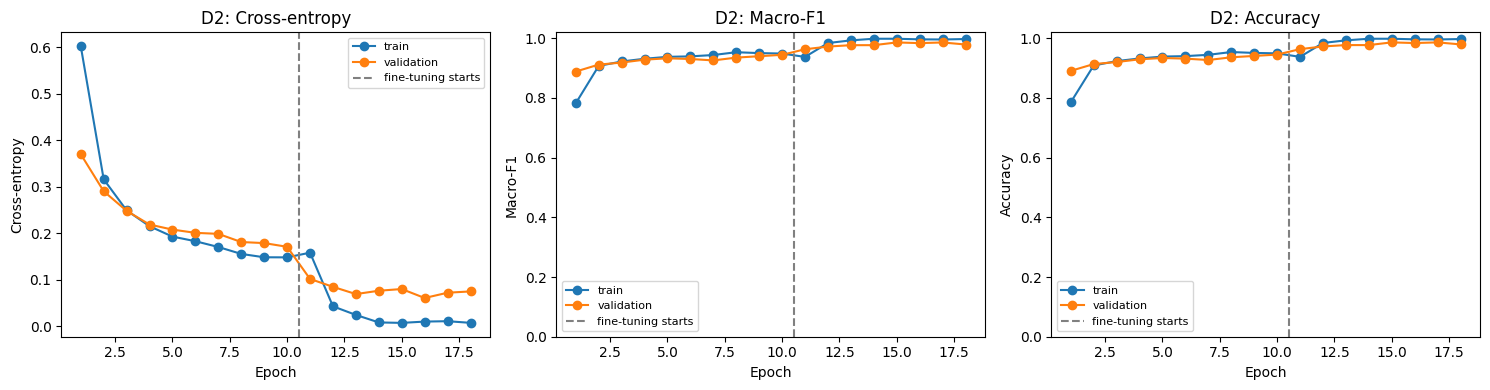

Selected checkpoint: {'run': 'D2', 'model': 'ResNet18', 'processing': 'CLAHE_then_median', 'val_accuracy': 0.9863636363636363, 'val_macro_f1': 0.9861798310978639, 'training_seconds': 155.69557070000155, 'checkpoint': 'outputs\\models\\D2_best.pt', 'best_phase': 'finetune', 'best_epoch': 15}


In [10]:
deep_results = {}
for run in ("D1", "D2"):
    deep_results[run] = train_deep(run, train_frame, val_frame)
    plot_learning_curves(run, deep_results[run]["history"])
    print("Selected checkpoint:", deep_results[run]["summary"])

## 2e. Save the training checkpoint for Step 3

The table below compares **validation scores only**. There is no test score in this notebook.
The SVM decision values saved with C2 predictions are not probabilities; D1/D2 probability
columns are softmax values from the selected checkpoints.

Rerunning training replaces this notebook's own model/report files. Step 1's manifest, processing
settings, figures and corrupted test images remain unchanged. Source-file hashes and package versions
are stored with the models so that a later evaluation can check it is using the same inputs.

In [11]:
validation_comparison = pd.DataFrame([
    c2_result["summary"], deep_results["D1"]["summary"], deep_results["D2"]["summary"],
])
validation_comparison.to_csv(TRAINING_DIR / "validation_comparison.csv", index=False)
write_json(TRAINING_DIR / "step2_run_settings.json", {
    "runs": ["C2", "D1", "D2"], "labels": LABELS, "class_to_id": CLASS_TO_ID,
    "seed": SEED, "source_hashes": SOURCE_HASHES, "processing_settings": SETTINGS,
    "feature_config": FEATURE_CONFIG, "svm_grid": SVM_GRID, "cnn_config": CNN_CONFIG,
    "package_versions": PACKAGE_VERSIONS, "test_evaluated": False,
})
if (file_sha256(MANIFEST_PATH) != SOURCE_HASHES["manifest_sha256"] or
        file_sha256(SETTINGS_PATH) != SOURCE_HASHES["processing_settings_sha256"]):
    raise RuntimeError("A Step 1 input changed while training; do not use these results.")
display(validation_comparison[["run", "processing", "val_macro_f1", "val_accuracy", "checkpoint"]])
print("Step 2 complete. Models and validation reports are saved; test evaluation is still pending.")

,run,processing,val_macro_f1,val_accuracy,checkpoint
0,C2,CLAHE_then_median,0.983709,0.984091,outputs\models\C2.joblib
1,D1,CLAHE,0.983853,0.984091,outputs\models\D1_best.pt
2,D2,CLAHE_then_median,0.986180,0.986364,outputs\models\D2_best.pt


Step 2 complete. Models and validation reports are saved; test evaluation is still pending.


| Output | Contents |
|---|---|
| `outputs/models/C2.joblib` | Selected training-fitted scaler and RBF SVM pipeline |
| `outputs/models/D1_best.pt`, `D2_best.pt` | Selected ResNet-18 state dictionaries and architecture/processing metadata |
| `outputs/models/*_metadata.json` | Label mapping, preprocessing, source hashes, versions and selection details |
| `outputs/training/C2/` | Full parameter-search table and validation reports |
| `outputs/training/D1/`, `D2/` | Per-epoch histories and validation reports |
| `outputs/training/validation_comparison.csv` | Comparison of selected models on validation images |
| `outputs/training/step2_run_settings.json` | The configuration shared with the next step |
| `outputs/figures/step2/` | Training processing preview, SVM search plots, learning curves and validation confusion matrices |

**Next: Step 3.** Freeze the selected models and settings. Load the original test rows from the
existing manifest and the four fixed conditions from `outputs/corrupted_test/corrupted_manifest.csv`.
Apply the same run-specific processing and model input transforms. Report test metrics separately
for clean, dark gamma 1.5, dark gamma 2.0, 1% noise and 3% noise, including preprocessing plus inference
time measured on the same hardware. Do not use those results to tune these models.

For later loading, C2 is a joblib pipeline. Each CNN checkpoint has `model_state_dict` plus
`metadata`; construct ResNet-18 with a three-output linear head, load that state dictionary, and
use evaluation mode. No model needs another ImageNet download once its selected state is saved.

API references: [Torchvision ResNet-18 and its input transforms](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html),
[PyTorch transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html),
[scikit-learn pipelines](https://scikit-learn.org/stable/modules/compose.html#pipeline),
and [scikit-image LBP](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.local_binary_pattern).